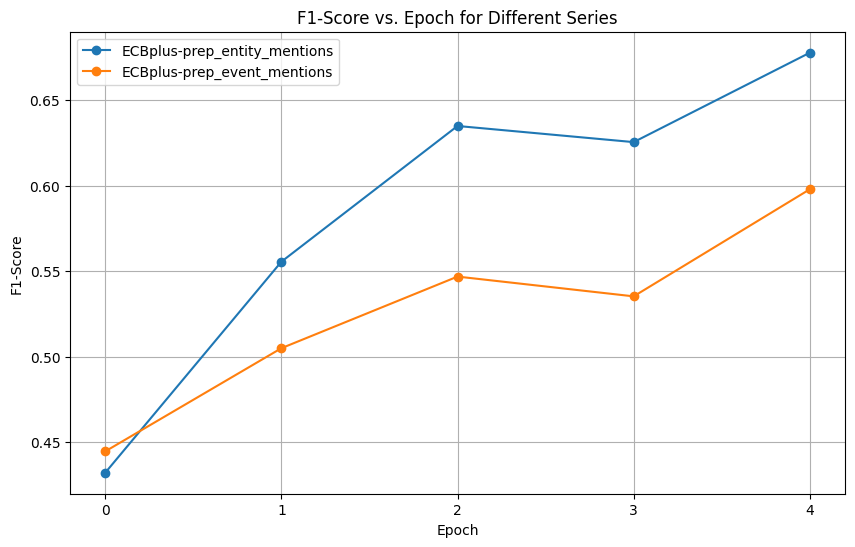

In [34]:
import json
import numpy as np
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import os
from evaluator import Evaluation
import torch 

def find_val_results_json_files(folder_path):
    # Initialize an empty list to store the paths of "val_results.json" files
    json_files = []

    # Walk through the directory and its subdirectories
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file == 'val_results.json':
                json_files.append(os.path.join(root, file))

    return json_files

    
 
def read_json_file(path):
    # Load the JSON data from the file
    with open(path, 'r') as json_file:
        data = json.load(json_file)

    # Initialize dictionaries to store F1-scores for each series
    f1_scores = {}

    # Initialize variables for legend_labels and series_data
    legend_labels = []
    series_data = []

    # Iterate through the numerical keys (0, 1, 2)
    for key, value in data.items():
        identifiers_list = [f"{x['dataset_name']}_{x['mention_type']}" for x in value['identifiers']]
        # Calculate F1-scores once for each unique identifier
        unique_keys = set(identifiers_list)
        for dataset_key in unique_keys:
            key_indices = np.where(np.array(identifiers_list) == dataset_key)[0]
            scores = np.array(value['scores'])[key_indices]
            labels = np.array(value['labels'])[key_indices]
            # f1 = f1_score(labels, scores, average='micro')  # You can choose a different averaging method if needed
            
            evaluator = Evaluation(torch.tensor(scores), torch.tensor(labels))
            f1 = evaluator.get_f1()
            # Append F1-score to the corresponding series
            if dataset_key in f1_scores:
                f1_scores[dataset_key].append(f1)
            else:
                f1_scores[dataset_key] = [f1]

    # Prepare data for plotting
    x_values = list(data.keys())  # Epochs

    for identifier_key, f1_series in f1_scores.items():
        legend_labels.append(identifier_key)
        series_data.append(f1_series)

    return x_values, legend_labels, series_data

def plot_data(x_values, legend_labels, series_data):
    # Create a plot
    plt.figure(figsize=(10, 6))
    for i, series in enumerate(series_data):
        plt.plot(x_values, series, marker='o', label=legend_labels[i])

    plt.xlabel('Epoch')
    plt.ylabel('F1-Score')
    plt.title('F1-Score vs. Epoch for each dataset')
    plt.legend()
    plt.grid(True)

    # Show the plot
    plt.show()

# Usage example
x_values, legend_labels, series_data = read_json_file('models/pairwise_scorers/large_256/val_results.json')
plot_data(x_values, legend_labels, series_data)


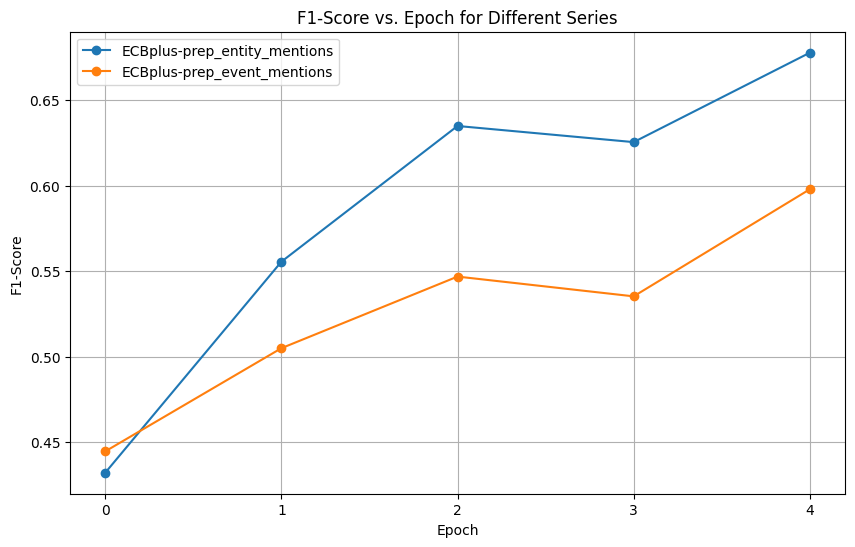

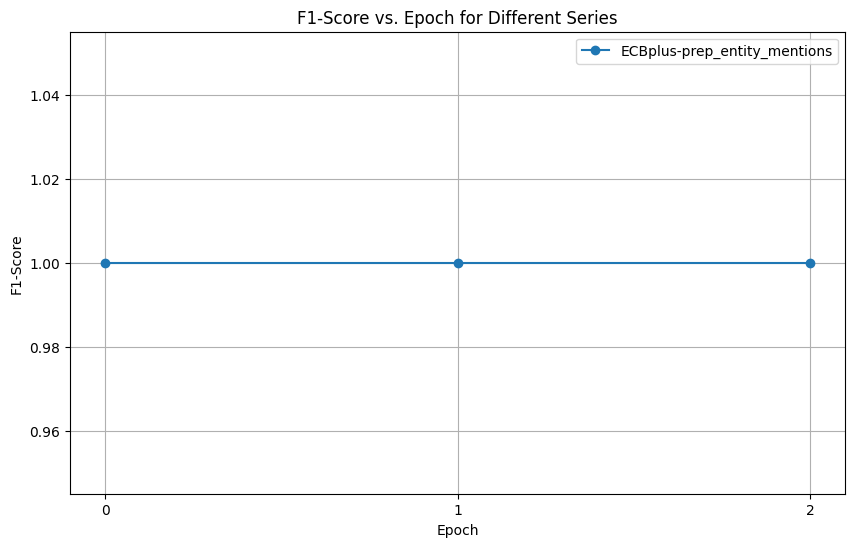

In [36]:
# Provide the path to the folder you want to search in (e.g., 'models/')
folder_path = 'models'
val_results_json_files = find_val_results_json_files(folder_path)

# Print the list of paths to "val_results.json" files
for file_path in val_results_json_files:
    x_values, legend_labels, series_data = read_json_file(file_path)
    plot_data(x_values, legend_labels, series_data)